First 5 Rows:
   Gender  Height  Weight  Index
0    Male     174      96      4
1    Male     189      87      2
2  Female     185     110      4
3  Female     195     104      3
4    Male     149      61      3

Dataset Shape: (500, 4)

Missing Values:
Gender    0
Height    0
Weight    0
Index     0
dtype: int64

Duplicate Rows: 11

Training Data: (391, 3)
Testing Data: (98, 3)

KNN MODEL EVALUATION
Accuracy: 0.8571428571428571

Classification Report:
              precision    recall  f1-score   support

           0       0.33      0.50      0.40         2
           1       0.33      0.25      0.29         4
           2       0.69      0.79      0.73        14
           3       0.80      0.62      0.70        13
           4       0.90      1.00      0.95        26
           5       1.00      0.95      0.97        39

    accuracy                           0.86        98
   macro avg       0.68      0.68      0.67        98
weighted avg       0.86      0.86      0.86        98



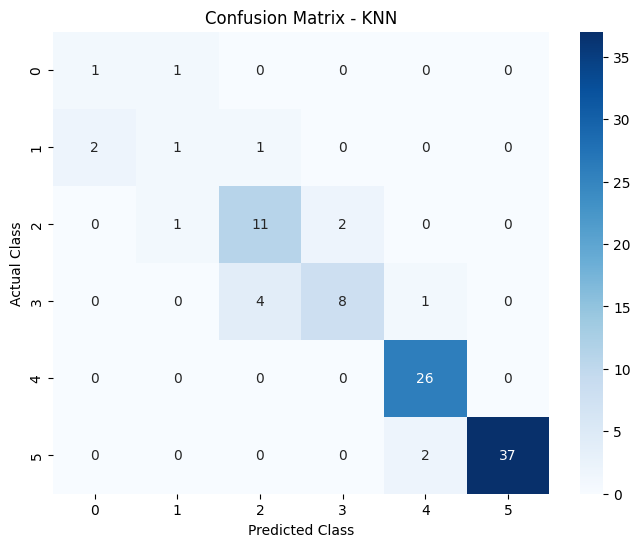


Best K Value: 3
Best CV Accuracy: 0.854


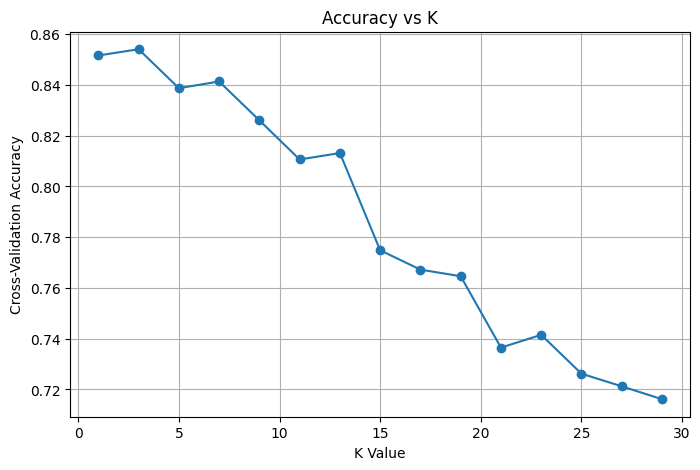


Final Model Accuracy: 0.9081632653061225


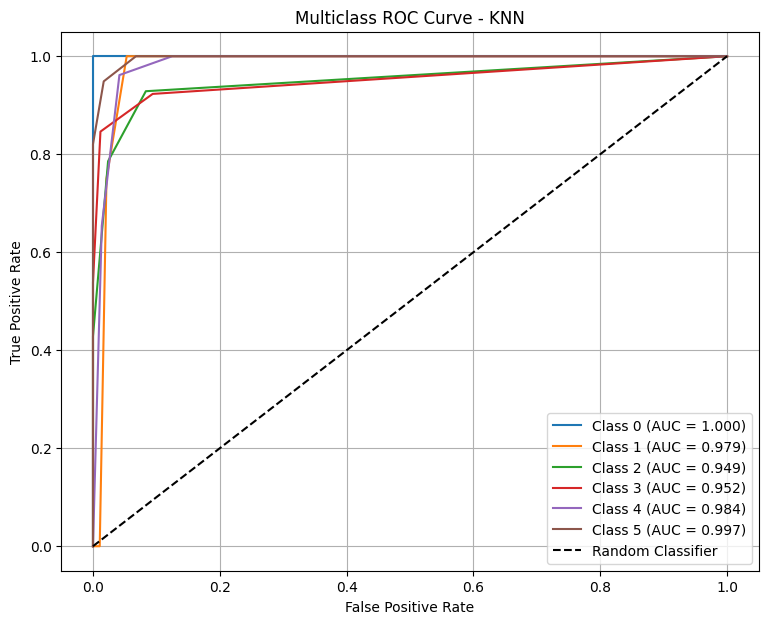


Overall Multiclass ROC-AUC Score: 0.977

New Person Prediction: Overweight


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    auc,
    roc_auc_score
)


file_path = "/content/500_Person_Gender_Height_Weight_Index (1).csv"

df = pd.read_csv(file_path)

print("First 5 Rows:")
print(df.head())

print("\nDataset Shape:", df.shape)


print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates().reset_index(drop=True)


df["Gender"] = df["Gender"].map({
    "Male": 1,
    "Female": 0
})

X = df[["Gender", "Height", "Weight"]]
y = df["Index"]


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data:", X_test.shape)


knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)

y_pred = knn_model.predict(X_test)


print("\nKNN MODEL EVALUATION")

print("Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

print("Precision:",
      precision_score(y_test, y_pred, average="weighted", zero_division=0))

print("Recall:",
      recall_score(y_test, y_pred, average="weighted", zero_division=0))

print("F1 Score:",
      f1_score(y_test, y_pred, average="weighted", zero_division=0))


cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - KNN")
plt.show()


k_values = range(1, 31, 2)
cv_scores = []

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for k in k_values:
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy"
    )

    cv_scores.append(scores.mean())

best_k = list(k_values)[np.argmax(cv_scores)]

print("\nBest K Value:", best_k)
print("Best CV Accuracy:", round(max(cv_scores), 3))

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), cv_scores, marker="o")
plt.xlabel("K Value")
plt.ylabel("Cross-Validation Accuracy")
plt.title("Accuracy vs K")
plt.grid()
plt.show()


final_model = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=best_k))
])

final_model.fit(X_train, y_train)

y_pred = final_model.predict(X_test)

print("\nFinal Model Accuracy:",
      accuracy_score(y_test, y_pred))


classes = final_model.named_steps["knn"].classes_

y_test_binary = label_binarize(
    y_test,
    classes=classes
)

y_prob = final_model.predict_proba(X_test)


plt.figure(figsize=(9, 7))

for i, class_label in enumerate(classes):

    fpr, tpr, thresholds = roc_curve(
        y_test_binary[:, i],
        y_prob[:, i]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        label=f"Class {class_label} (AUC = {roc_auc:.3f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve - KNN")
plt.legend()
plt.grid()
plt.show()

overall_auc = roc_auc_score(
    y_test,
    y_prob,
    multi_class="ovr",
    average="macro",
    labels=classes
)

print("\nOverall Multiclass ROC-AUC Score:",
      round(overall_auc, 3))


new_person = pd.DataFrame({
    "Gender": [1],
    "Height": [175],
    "Weight": [80]
})

prediction = final_model.predict(new_person)

labels = {
    0: "Extremely Weak",
    1: "Weak",
    2: "Normal",
    3: "Overweight",
    4: "Obesity",
    5: "Extreme Obesity"
}

print("\nNew Person Prediction:",
      labels[prediction[0]])
